# AGML-DenseCBAM system architecture, module by module

This notebook follows the **current code files**, where each module of the system lives in its own file. It uses the Final V2 settings. The Final V2 results themselves were produced by an earlier single-file version of the trainer with the same design; notebook 2 contains that exact file.

The system has six modules, in the order the code runs them:

![Figure 4.1: system architecture](figures/architecture_six_modules.png)

 Each section below explains one module in plain words, shows its code, and then runs a small demonstration on the real data.

| Module | What it does | Main code |
|---|---|---|
| 1. Data Audit | Finds duplicate images and removes images that carry both labels | `scan_source_images`, `prepare_unique_items` |
| 2. Five-Fold Partitioning | Splits the 3,002 kept images into five folds, each with training, validation and test parts | `grouped_stratified_folds`, `create_folds`, `index_split_dataset` |
| 3. Input Preparation | Loads, resizes and scales each image, and adds an artifact in the mixed cases | `apply_artifact`, `TMJSequence` |
| 4. Model Building | Builds one model for the case: the benchmark (C1, C2) or AGML-DenseCBAM (C3, C4) | `build_benchmark_model`, `build_proposed_model` |
| 5. Training and Selection | Trains that model and keeps the epoch with the lowest validation loss | `compile_model`, callbacks, `model.fit` |
| 6. Evaluation and Interpretation | Scores the selected model on the test fold and draws Grad-CAM heatmaps | `collect_predictions`, metrics, `gradcam` |

**The four cases** are two models times two kinds of training images:

| | Trained on clean images | Trained with artifacts added |
|---|---|---|
| Benchmark (reconstructed attention-based DenseNet201) | C1 | C2 |
| AGML-DenseCBAM (proposed) | C3 | C4 |

Every case runs through the same six modules on the same five folds. Only Module 3 (artifacts on or off) and Module 4 (which model) change between cases.

In [1]:
# Settings for this notebook. Only CASE and FOLD need changing to look at another case.
import os
import sys
from pathlib import Path

# The project folder holds scripts/, data/, data_5_fold/, results/final_v2/ and notebooks/. It is found automatically:
# in Colab, the Drive folder below; elsewhere, the repository this notebook sits in. AGML_PROJECT_ROOT overrides both.
COLAB_PROJECT_FOLDER = "/content/drive/MyDrive/AGML-DenseCBAM"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path(COLAB_PROJECT_FOLDER)
except ImportError:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = Path(os.environ.get("AGML_PROJECT_ROOT", PROJECT_ROOT)).resolve()
assert (PROJECT_ROOT / "data_5_fold").is_dir(), f"No data_5_fold/ in {PROJECT_ROOT}. Set AGML_PROJECT_ROOT to the project folder."
print("Project folder:", PROJECT_ROOT)
SOURCE_IMAGES = PROJECT_ROOT / "data"                # the original extracted images (3,425 files)
FOLDS_ROOT = PROJECT_ROOT / "data_5_fold"            # the five saved folds used by every case
SAVED_V2 = PROJECT_ROOT / "results" / "final_v2"     # the saved Final V2 models and result files

CASE = "C4"        # C1, C2, C3 or C4
FOLD = "fold_1"    # fold_1 to fold_5

RUN_EVALUATION = True   # Module 6 demo: load the saved Final V2 model and score its test fold (about 2 minutes)
RUN_TRAINING = False    # Module 5: train this case and fold from scratch (about an hour); not needed for the discussion

CASES = {"C1": ("benchmark", "clean"), "C2": ("benchmark", "artifact_mix"), "C3": ("proposed", "clean"), "C4": ("proposed", "artifact_mix")}
CASE_FOLDERS = {"C1": "benchmark_clean", "C2": "benchmark_artifact_mix", "C3": "proposed_clean", "C4": "proposed_artifact_mix"}

Project folder: /home/solyvie/workspace/thesis-projects/working-run/AGML-DenseCBAM


## Code files

The code is imported from the repository. `show(...)` prints a function's code, so each section shows exactly what runs.

| Module | File |
|---|---|
| 1, 2 | `scripts/make_5fold_dataset.py` (fold creation), `scripts/pipeline/data.py` (reading folds) |
| 3 | `scripts/pipeline/artifacts.py`, `scripts/pipeline/data.py` |
| 4, 5 | `scripts/pipeline/models.py` |
| 6 | `scripts/pipeline/evaluation.py`, `scripts/generate_gradcam.py` |
| All, in order | `scripts/pipeline/experiment.py` |

In [2]:
import inspect
import sys
from IPython.display import Markdown, display

sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

from make_5fold_dataset import (scan_source_images, prepare_unique_items, write_duplicate_audit, grouped_stratified_folds,
                                grouped_train_val_split, assert_no_group_overlap, create_folds)
from pipeline.config import RunConfig, configure_tensorflow, ARTIFACT_LABELS, DISPLAY_LABELS
from pipeline.data import index_split_dataset, validate_split_integrity, validate_manifest_integrity, TMJSequence, balanced_class_weights
from pipeline.artifacts import add_motion_blur, add_gaussian_noise, add_metal_streak, apply_artifact, densenet_preprocess
from pipeline.models import AttentionBlock, make_backbone, build_benchmark_model, build_proposed_model, compile_model, _training_callbacks, fit_model
from pipeline.evaluation import collect_predictions, expected_calibration_error
from pipeline.experiment import run_one_fold, run_case
from generate_gradcam import gradcam, overlay_heatmap, TARGET_LAYERS


def show(obj):
    """Prints the code of a function or class as a code block that follows the editor's light or dark theme."""
    display(Markdown(f"```python\n{inspect.getsource(obj)}\n```"))

I0000 00:00:1794149888.330978    5602 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794149890.293710    5602 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
# The Final V2 settings, as recorded in results/final_v2/<case>/run_config.json.
def make_config(case):
    model_type, scenario = CASES[case]
    return RunConfig(
        folds_root=FOLDS_ROOT,
        output_dir=PROJECT_ROOT / "results" / "notebook_runs" / CASE_FOLDERS[case],  # never results/final_v2
        model_type=model_type,
        scenario=scenario,
        image_size=(224, 224),
        batch_size=8,
        epochs=50,
        learning_rate=1e-4,
        l2_strength=1e-2,
        random_state=42,
        freeze_backbone=False,
        tmd_loss_weight=1.0,
        artifact_loss_weight=0.3,
        fold_limit=None,
        single_fold=FOLD,
        verify_integrity=True,
        mixed_precision=True,
        class_weighting=True,
    )

config = make_config(CASE)
model_type, scenario = CASES[CASE]
multi_task = model_type == "proposed"
configure_tensorflow(config)  # mixed precision on the GPU, as in the real runs
print(CASE, "=", model_type, "model,", scenario, "images")

TensorFlow precision policy: mixed_float16
C4 = proposed model, artifact_mix images


## Module 1. Data Audit

**What it does.** The source study gave us 3,425 image files labeled Normal or Subluxation. Many files are exact copies of each other. The audit reads every file, computes a fingerprint of its content (SHA-256), and groups identical files together.

- Copies with the same label are kept once.
- Eight images appear under **both** labels. They are removed, because we cannot tell which label is right. No label is ever changed.

**Input:** the folder of source images. **Output:** 3,002 unique images (1,359 Normal, 1,643 Subluxation), plus an audit file listing every duplicate group.

In Figure 4.1 this is Module 1.

In [4]:
show(scan_source_images)
show(prepare_unique_items)

```python
def scan_source_images(input_root: Path) -> List[SourceImage]:
    images: List[SourceImage] = []
    class_to_idx = {name: idx for idx, name in enumerate(CLASS_NAMES)}

    for split_name in SOURCE_SPLITS:
        split_dir = input_root / split_name
        if not split_dir.exists():
            raise FileNotFoundError(f"Missing source split folder: {split_dir}")

        for class_name in CLASS_NAMES:
            class_dir = split_dir / class_name
            if not class_dir.exists():
                raise FileNotFoundError(f"Missing class folder: {class_dir}")

            for file_path in sorted(class_dir.rglob("*")):
                if file_path.is_file() and file_path.suffix.lower() in IMAGE_EXTS:
                    images.append(
                        SourceImage(
                            path=file_path,
                            class_name=class_name,
                            label=class_to_idx[class_name],
                            original_split=split_name,
                            content_sha256=sha256_file(file_path),
                        )
                    )

    if not images:
        raise ValueError(f"No images found under {input_root}")
    return images

```

```python
def prepare_unique_items(
    images: Sequence[SourceImage],
    output_root: Path,
    input_root: Path,
    conflict_policy: str,
    group_mapping: Dict[str, str],
) -> List[Item]:
    by_content: DefaultDict[str, List[SourceImage]] = defaultdict(list)
    for image in images:
        by_content[image.content_sha256].append(image)

    duplicate_groups, conflicting_groups = write_duplicate_audit(output_root, by_content)
    duplicate_copies = sum(len(members) - 1 for members in by_content.values())
    print(
        f"Content audit: {len(images)} files, {len(by_content)} unique images, "
        f"{duplicate_groups} duplicate groups, {duplicate_copies} extra copies, "
        f"{conflicting_groups} conflicting-label groups."
    )
    print(f"Audit written to: {(output_root / 'duplicate_audit.csv').resolve()}")

    if conflicting_groups and conflict_policy == "error":
        raise ValueError(
            f"Found {conflicting_groups} exact-image groups with conflicting labels. "
            "Review duplicate_audit.csv and correct the source labels. If exclusion is "
            "approved and documented, rerun with --conflict_policy exclude."
        )

    items: List[Item] = []
    excluded_files = 0
    for digest, members in sorted(by_content.items()):
        labels = {member.class_name for member in members}
        if len(labels) > 1:
            excluded_files += len(members)
            continue

        representative = sorted(members, key=lambda member: normalized_path(member.path))[0]
        items.append(
            Item(
                src_path=representative.path,
                class_name=representative.class_name,
                label=representative.label,
                original_split=representative.original_split,
                content_sha256=digest,
                duplicate_paths=tuple(sorted(normalized_path(member.path) for member in members)),
                group_id=resolve_group_id(members, group_mapping, input_root),
            )
        )

    if excluded_files:
        print(f"Excluded {excluded_files} files from conflicting-label duplicate groups.")
    if not items:
        raise ValueError("No usable unique images remain after duplicate handling.")
    return items

```

In [5]:
# Run the audit on the real source images. The audit file is written to a temporary folder,
# so the saved folds are not touched.
import tempfile
import pandas as pd

images = scan_source_images(SOURCE_IMAGES)
print(f"Source files: {len(images)}")
audit_folder = Path(tempfile.mkdtemp())
items = prepare_unique_items(images, output_root=audit_folder, input_root=SOURCE_IMAGES, conflict_policy="exclude", group_mapping={})
print(f"Kept: {len(items)} unique images")
print(pd.Series([item.class_name for item in items]).value_counts().to_string())

Source files: 3425
Content audit: 3425 files, 3010 unique images, 361 duplicate groups, 415 extra copies, 8 conflicting-label groups.
Audit written to: /tmp/tmphk0z2uy4/duplicate_audit.csv
Excluded 17 files from conflicting-label duplicate groups.
Kept: 3002 unique images
subluxation    1643
normal         1359


## Module 2. Five-Fold Partitioning

**What it does.** The 3,002 images are split into five folds. In each fold:

- about one fifth of the images (600 or 601) are the **test** part,
- about one seventh of the rest (343 or 344) are the **validation** part, used to pick the best epoch in Module 5,
- the remaining 2,058 are the **training** part.

Every image is in the test part of exactly one fold. The split keeps the Normal/Subluxation ratio about the same in every part, and it uses a fixed seed (42), so the same folds come out every time. All four cases use these same saved folds, which is what makes the comparisons fair.

`create_folds` copies the images into `data_5_fold/fold_k/{train,validation,test}/` and writes a `manifest.csv`. `index_split_dataset` reads a fold back for training and checks that no image appears in two parts.

In Figure 4.1 this is Module 2.

In [6]:
show(grouped_stratified_folds)
show(grouped_train_val_split)
show(create_folds)
show(index_split_dataset)

```python
def grouped_stratified_folds(
    items: Sequence[Item],
    n_splits: int,
    random_state: int,
) -> List[List[int]]:
    # Balance classes while keeping groups intact.
    if n_splits < 2:
        raise ValueError("n_splits must be at least 2")

    grouped: DefaultDict[str, List[int]] = defaultdict(list)
    for index, item in enumerate(items):
        grouped[item.group_id].append(index)
    if len(grouped) < n_splits:
        raise ValueError(f"Only {len(grouped)} independent groups are available for {n_splits} folds.")

    total = Counter(item.label for item in items)
    for label in range(len(CLASS_NAMES)):
        groups_with_label = sum(any(items[i].label == label for i in indices) for indices in grouped.values())
        if groups_with_label < n_splits:
            raise ValueError(
                f"Class {CLASS_NAMES[label]!r} appears in only {groups_with_label} independent groups; "
                f"cannot create {n_splits} grouped folds."
            )

    rng = random.Random(random_state)
    group_entries = []
    for group_id, indices in grouped.items():
        counts = Counter(items[i].label for i in indices)
        group_entries.append((group_id, indices, counts, rng.random()))
    group_entries.sort(key=lambda entry: (-len(entry[1]), -max(entry[2].values()), entry[3]))

    fold_indices: List[List[int]] = [[] for _ in range(n_splits)]
    fold_counts = [Counter() for _ in range(n_splits)]
    target = {label: total[label] / n_splits for label in range(len(CLASS_NAMES))}

    def assignment_score(candidate_fold: int, counts: Counter) -> Tuple[float, int, int]:
        score = 0.0
        for label in range(len(CLASS_NAMES)):
            hypothetical = [
                fold_counts[fold][label] + (counts[label] if fold == candidate_fold else 0)
                for fold in range(n_splits)
            ]
            mean_count = sum(hypothetical) / n_splits
            score += sum((count - mean_count) ** 2 for count in hypothetical) / max(target[label], 1.0)
        hypothetical_sizes = [
            len(fold_indices[fold]) + (sum(counts.values()) if fold == candidate_fold else 0)
            for fold in range(n_splits)
        ]
        mean_size = sum(hypothetical_sizes) / n_splits
        score += sum((size - mean_size) ** 2 for size in hypothetical_sizes) / max(mean_size, 1.0)
        return score, len(fold_indices[candidate_fold]), candidate_fold

    for _, indices, counts, _ in group_entries:
        best_fold = min(range(n_splits), key=lambda fold: assignment_score(fold, counts))
        fold_indices[best_fold].extend(indices)
        fold_counts[best_fold].update(counts)

    return [sorted(indices) for indices in fold_indices]

```

```python
def grouped_train_val_split(
    items: Sequence[Item],
    candidate_indices: Sequence[int],
    val_size: float,
    random_state: int,
) -> Tuple[List[int], List[int]]:
    if not 0 < val_size < 1:
        raise ValueError("val_size must be between 0 and 1")

    subset = [items[index] for index in candidate_indices]
    approximate_folds = max(2, round(1.0 / val_size))
    approximate_folds = min(approximate_folds, len({item.group_id for item in subset}))
    candidate_val_folds = grouped_stratified_folds(subset, approximate_folds, random_state)
    target_size = len(subset) * val_size
    val_relative = min(candidate_val_folds, key=lambda indices: abs(len(indices) - target_size))
    val_set = {candidate_indices[index] for index in val_relative}
    train_indices = sorted(index for index in candidate_indices if index not in val_set)
    val_indices = sorted(val_set)
    return train_indices, val_indices

```

```python
def create_folds(
    items: Sequence[Item],
    output_root: Path,
    n_splits: int = 5,
    val_size: float = 0.15,
    random_state: int = 42,
) -> None:
    test_folds = grouped_stratified_folds(items, n_splits=n_splits, random_state=random_state)
    all_indices = set(range(len(items)))

    for fold_number, test_indices in enumerate(test_folds, start=1):
        train_val_indices = sorted(all_indices - set(test_indices))
        train_indices, val_indices = grouped_train_val_split(
            items,
            train_val_indices,
            val_size=val_size,
            random_state=random_state + fold_number,
        )
        split_indices = {
            "train": train_indices,
            "validation": val_indices,
            "test": test_indices,
        }
        assert_no_group_overlap(items, split_indices)

        fold_root = output_root / f"fold_{fold_number}"
        ensure_fold_dirs(fold_root)
        manifest_rows = []

        for split_name, indices in split_indices.items():
            for index in indices:
                item = items[index]
                destination = fold_root / split_name / item.class_name / safe_unique_name(item)
                shutil.copy2(item.src_path, destination)
                manifest_rows.append(
                    {
                        "source_path": normalized_path(item.src_path),
                        "copied_path": normalized_path(destination),
                        "class_name": item.class_name,
                        "fold_split": split_name,
                        "content_sha256": item.content_sha256,
                        "group_id": item.group_id,
                        "duplicate_count": len(item.duplicate_paths),
                        "duplicate_paths_json": json.dumps(item.duplicate_paths),
                    }
                )

        with (fold_root / "manifest.csv").open("w", newline="", encoding="utf-8") as handle:
            writer = csv.DictWriter(handle, fieldnames=list(manifest_rows[0]))
            writer.writeheader()
            writer.writerows(manifest_rows)

        counts = {
            split: Counter(items[index].class_name for index in indices)
            for split, indices in split_indices.items()
        }
        print(
            f"[fold_{fold_number}] "
            + ", ".join(
                f"{split}={len(split_indices[split])} {dict(counts[split])}"
                for split in ["train", "validation", "test"]
            )
        )

```

```python
def index_split_dataset(root: Path, verify_integrity: bool = True) -> pd.DataFrame:
    rows: List[Dict[str, object]] = []
    class_to_idx = {name: idx for idx, name in enumerate(TMD_LABELS)}
    for split in ["train", "validation", "test"]:
        split_dir = root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Missing split folder: {split_dir}")
        for class_name in TMD_LABELS:
            class_dir = split_dir / class_name
            if not class_dir.exists():
                raise FileNotFoundError(f"Missing class folder: {class_dir}")
            for path in sorted(class_dir.rglob("*")):
                if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                    rows.append(
                        {
                            "filepath": str(path),
                            "split": split,
                            "class_name": class_name,
                            "tmd_label": class_to_idx[class_name],
                        }
                    )
    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError(f"No images found under {root}")
    if verify_integrity:
        validate_split_integrity(df)
        validate_manifest_integrity(root, expected_image_count=len(df))
    return df

```

In [7]:
# Recompute the five test folds from the audited images and compare them with the saved folds.
# create_folds is not run here, because it would rewrite data_5_fold.
test_folds = grouped_stratified_folds(items, n_splits=5, random_state=42)
for number, indices in enumerate(test_folds, start=1):
    manifest = pd.read_csv(FOLDS_ROOT / f"fold_{number}" / "manifest.csv")
    saved = set(manifest.loc[manifest.fold_split == "test", "content_sha256"])
    recomputed = {items[i].content_sha256 for i in indices}
    print(f"fold_{number}: {len(recomputed)} test images, identical to the saved fold: {recomputed == saved}")

fold_1: 601 test images, identical to the saved fold: True


fold_2: 600 test images, identical to the saved fold: True
fold_3: 600 test images, identical to the saved fold: True
fold_4: 601 test images, identical to the saved fold: True
fold_5: 600 test images, identical to the saved fold: True


In [8]:
# Read one saved fold the way training does, with the leakage checks switched on.
fold_df = index_split_dataset(FOLDS_ROOT / FOLD, verify_integrity=True)
fold_df.groupby(["split", "class_name"]).size().unstack()

class_name,normal,subluxation
split,,
test,272,329
train,931,1127
validation,156,187


## Module 3. Input Preparation

**What it does.** Turns each image file into the numbers the model reads. Every image is loaded, converted to RGB, resized to 224 × 224 pixels and scaled to the range −1 to 1.

The case decides one thing here: whether artifacts are added.

- **Clean cases (C1, C3):** no artifact is ever added.
- **Mixed cases (C2, C4):** each image gets one of four conditions with equal chance: none, motion blur, Gaussian noise or a metal streak. The program records which one it chose; that record is the answer key for the auxiliary task.

There are three lanes, one per part of the fold:

| Lane | Flip | Artifact | Why |
|---|---|---|---|
| Training | Random left–right flip, half the time | A new random artifact every epoch | More variety for learning |
| Validation | None | Fixed per image | Every epoch, and every model, is judged on the same inputs |
| Test | None | Fixed per image | Every model is tested on exactly the same inputs |

The fixed artifact comes from the image's file name and the seed, so C2 and C4 see identical test images.

In Figure 4.1 this is Module 3.

In [9]:
show(apply_artifact)
show(add_metal_streak)
show(densenet_preprocess)
show(TMJSequence)

```python
def apply_artifact(
    image: np.ndarray,
    artifact_label: int,
    rng: np.random.Generator,
) -> np.ndarray:
    if artifact_label == 0:
        return image
    if artifact_label == 1:
        return add_motion_blur(image, kernel_size=int(rng.choice([5, 7, 9])))
    if artifact_label == 2:
        return add_gaussian_noise(image, rng, sigma=float(rng.uniform(8.0, 12.0)))
    if artifact_label == 3:
        return add_metal_streak(image, rng, num_streaks=int(rng.choice([1, 2])))
    raise ValueError(f"Unknown artifact label: {artifact_label}")

```

```python
def add_metal_streak(
    image: np.ndarray,
    rng: np.random.Generator,
    num_streaks: int = 2,
) -> np.ndarray:
    # Add visible localized V2 metal streaks.
    h, w = image.shape[:2]
    output = image.astype(np.float32).copy()
    combined_mask = np.zeros((h, w), dtype=np.float32)
    for _ in range(max(1, num_streaks)):
        mask = np.zeros((h, w), dtype=np.float32)
        y_start = int(rng.integers(0, h))
        y_end = int(np.clip(y_start + rng.integers(-h // 3, h // 3 + 1), 0, h - 1))
        cv2.line(
            mask,
            (0, y_start),
            (w - 1, y_end),
            1.0,
            int(rng.integers(2, 5)),
        )
        mask = cv2.GaussianBlur(mask, (0, 0), sigmaX=float(rng.uniform(1.5, 2.5)))
        maximum = float(mask.max())
        if maximum > 0:
            mask /= maximum
        combined_mask = np.maximum(combined_mask, mask * float(rng.uniform(80.0, 110.0)))

    transformed = ensure_uint8(output + combined_mask[..., None])
    if np.array_equal(transformed, image):
        transformed = ensure_uint8(output - combined_mask[..., None])
    if np.array_equal(transformed, image):
        raise RuntimeError("V2 metal-streak transform produced no pixel change.")
    return transformed

```

```python
def densenet_preprocess(image: np.ndarray) -> np.ndarray:
    # Map image values from [0, 255] to [-1, 1].
    return image.astype(np.float32) / 127.5 - 1.0

```

```python
class TMJSequence(KerasSequence):
    def __init__(
        self,
        dataframe: pd.DataFrame,
        image_size: Tuple[int, int],
        batch_size: int,
        multi_task: bool,
        scenario: str,
        training: bool,
        seed: int,
        tmd_class_weights: Dict[int, float] | None = None,
        recipe: str = "v2",
        **kwargs,
    ) -> None:
        super().__init__(**kwargs)
        if recipe not in ("v2", "v3"):
            raise ValueError(f"Unknown recipe: {recipe}")
        self.df = dataframe.reset_index(drop=True).copy()
        self.image_size = image_size  # (height, width)
        self.recipe = recipe
        # shortcut: unbounded in-memory cache (~0.9 GB per fold at 448x224); fine for 3,002 images.
        self._cache: Dict[str, np.ndarray] = {}
        self.batch_size = batch_size
        self.multi_task = multi_task
        self.scenario = scenario
        self.training = training
        self.seed = seed
        self.tmd_class_weights = tmd_class_weights
        self.shuffle_rng = np.random.default_rng(seed)
        self.indices = np.arange(len(self.df))
        self.epoch = -1
        self.on_epoch_end()

    def __len__(self) -> int:
        return math.ceil(len(self.df) / self.batch_size)

    def on_epoch_end(self) -> None:
        if self.training:
            self.epoch += 1
            self.shuffle_rng.shuffle(self.indices)

    def _training_rng(self, filepath: str) -> np.random.Generator:
        sample_id = Path(filepath).name
        digest = hashlib.sha256(
            f"{self.seed}:{self.epoch}:{sample_id}".encode("utf-8")
        ).digest()
        return np.random.default_rng(int.from_bytes(digest[:8], "little"))

    def _evaluation_rng(self, filepath: str) -> np.random.Generator:
        # Fold filenames contain stable source hashes.
        sample_id = Path(filepath).name
        digest = hashlib.sha256(f"{self.seed}:{sample_id}".encode("utf-8")).digest()
        return np.random.default_rng(int.from_bytes(digest[:8], "little"))

    def _artifact_for(self, rng: np.random.Generator) -> int:
        if self.scenario == "clean":
            return 0
        return int(rng.integers(0, len(ARTIFACT_LABELS)))

    def evaluation_artifact_label(self, filepath: str) -> int:
        if self.training:
            raise RuntimeError("Deterministic artifact labels are only available for evaluation generators.")
        return self._artifact_for(self._evaluation_rng(filepath))

    def _augmentation_rng(self, filepath: str) -> np.random.Generator:
        # Separate stream so V3 augmentation leaves artifact draws identical to V2.
        digest = hashlib.sha256(
            f"augment:{self.seed}:{self.epoch}:{Path(filepath).name}".encode("utf-8")
        ).digest()
        return np.random.default_rng(int.from_bytes(digest[:8], "little"))

    def _load_image(self, filepath: str) -> np.ndarray:
        # Downstream transforms never modify the cached array in place.
        cached = self._cache.get(filepath)
        if cached is not None:
            return cached
        image = cv2.imread(filepath)
        if image is None:
            raise ValueError(f"Failed to load image: {filepath}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        height, width = self.image_size
        image = cv2.resize(image, (width, height), interpolation=cv2.INTER_AREA)
        self._cache[filepath] = image
        return image

    def __getitem__(self, index: int):
        batch_df = self.df.iloc[self.indices[index * self.batch_size : (index + 1) * self.batch_size]]
        images: List[np.ndarray] = []
        tmd_labels: List[int] = []
        artifact_labels: List[int] = []
        for row in batch_df.itertuples(index=False):
            image = self._load_image(row.filepath)
            item_rng = self._training_rng(row.filepath) if self.training else self._evaluation_rng(row.filepath)
            if self.training and item_rng.random() < 0.5:
                image = cv2.flip(image, 1)
            if self.training and self.recipe == "v3":
                image = mild_augment(image, self._augmentation_rng(row.filepath))
            artifact_label = self._artifact_for(item_rng)
            preprocess = densenet_torch_preprocess if self.recipe == "v3" else densenet_preprocess
            image = preprocess(apply_artifact(image, artifact_label, item_rng))
            images.append(image)
            tmd_labels.append(int(row.tmd_label))
            artifact_labels.append(int(artifact_label))

        x = np.stack(images)
        y_tmd = to_categorical(np.array(tmd_labels), num_classes=len(TMD_LABELS))
        y_artifact = to_categorical(np.array(artifact_labels), num_classes=len(ARTIFACT_LABELS))
        if self.multi_task:
            targets = {"tmd_output": y_tmd, "artifact_output": y_artifact}
            if self.training and self.tmd_class_weights:
                sample_weights = {
                    "tmd_output": np.asarray(
                        [self.tmd_class_weights[label] for label in tmd_labels],
                        dtype=np.float32,
                    ),
                    "artifact_output": np.ones(len(tmd_labels), dtype=np.float32),
                }
                return x, targets, sample_weights
            return x, targets

        if self.training and self.tmd_class_weights:
            sample_weights = np.asarray(
                [self.tmd_class_weights[label] for label in tmd_labels],
                dtype=np.float32,
            )
            return x, y_tmd, sample_weights
        return x, y_tmd

```

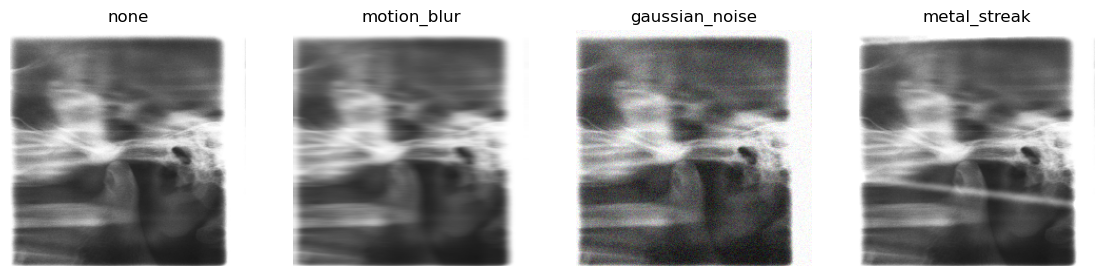

In [10]:
# One test image with each of the four generated conditions.
import cv2
import numpy as np
import matplotlib.pyplot as plt

sample_path = fold_df[fold_df.split == "test"].filepath.iloc[0]
image = cv2.resize(cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB), (224, 224), interpolation=cv2.INTER_AREA)
figure, axes = plt.subplots(1, 4, figsize=(14, 4))
for label, axis in enumerate(axes):
    axis.imshow(apply_artifact(image, label, np.random.default_rng(7)))
    axis.set_title(ARTIFACT_LABELS[label])
    axis.axis("off")
plt.show()

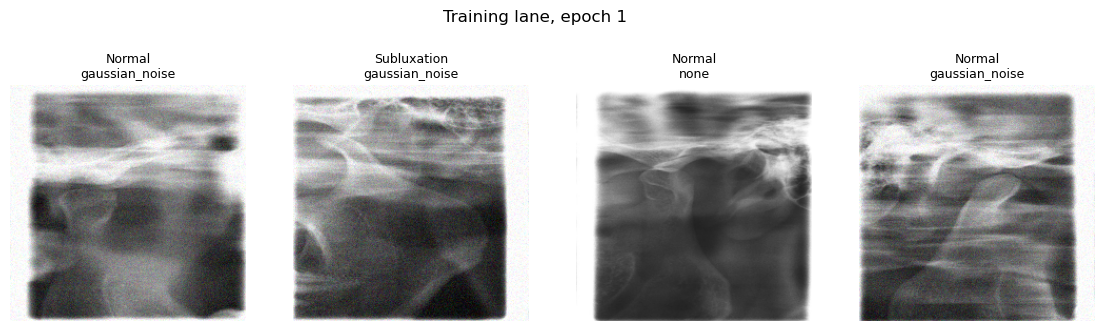

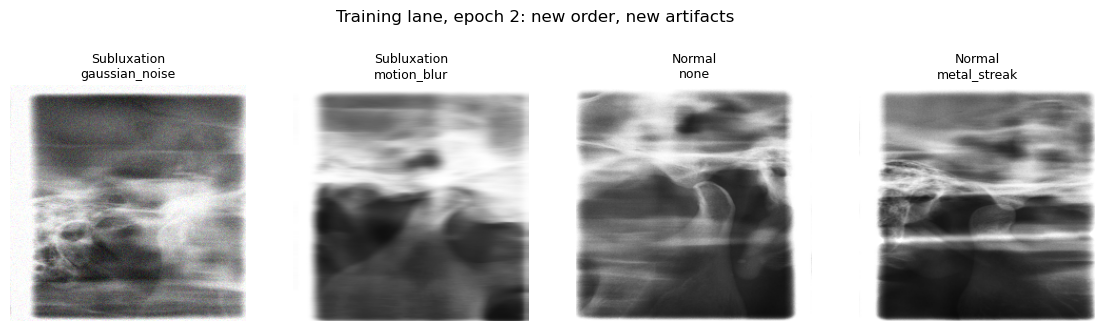

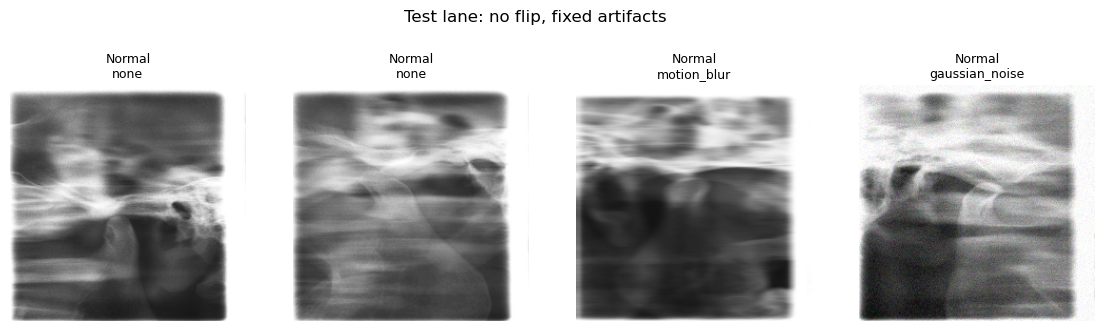

In [11]:
# The three lanes for a mixed case. Each panel shows the image the model receives, with its label and artifact.
def show_batch(sequence, title, count=4):
    x, y = sequence[0][:2]
    figure, axes = plt.subplots(1, count, figsize=(14, 4))
    for i, axis in enumerate(axes):
        tmd = DISPLAY_LABELS[int(np.argmax(y["tmd_output"][i]))]
        artifact = ARTIFACT_LABELS[int(np.argmax(y["artifact_output"][i]))]
        axis.imshow(np.clip((x[i] + 1.0) * 127.5, 0, 255).astype(np.uint8))
        axis.set_title(f"{tmd}\n{artifact}", fontsize=9)
        axis.axis("off")
    figure.suptitle(title)
    plt.show()

lanes = {split: TMJSequence(fold_df[fold_df.split == split], (224, 224), 8, True, "artifact_mix", split == "train", 42)
         for split in ("train", "validation", "test")}
show_batch(lanes["train"], "Training lane, epoch 1")
lanes["train"].on_epoch_end()
show_batch(lanes["train"], "Training lane, epoch 2: new order, new artifacts")
show_batch(lanes["test"], "Test lane: no flip, fixed artifacts")

## Module 4. Model Building

**What it does.** Builds the one model the case needs. C1 and C2 build the benchmark; C3 and C4 build AGML-DenseCBAM. A case never builds or combines both. Both models start from the same DenseNet201 backbone with ImageNet weights, and the whole backbone is trained.

**Benchmark (reconstructed from Sancar et al.):**

1. Take the earlier DenseNet feature map `pool3_relu` and apply **self-attention** to it.
2. Shrink it (4 × 4 average pooling) and project it to match the last feature map.
3. Join it with the last DenseNet feature map, `conv5_block32_concat`, and mix them with a 1 × 1 convolution.
4. Classifier head: global average pooling, Dense 1,024, dropout, batch normalization, Dense 128, then **Normal / Subluxation**.

**AGML-DenseCBAM (proposed):** one shared backbone, two heads.

1. **Main head:** apply **CBAM** to the last feature map (channel attention, then spatial attention), then the same style of classifier head, ending in **Normal / Subluxation** (`tmd_output`).
2. **Auxiliary head:** taken from the last feature map **before** CBAM. Average and max pooling are joined, then Dense 256 and dropout, ending in the **four artifact conditions** (`artifact_output`).

The auxiliary head sits before CBAM so that attention cannot hide the artifact evidence from it. Both heads train the shared backbone together; that sharing is the multi-task part.

In Figure 4.1 this is Module 4.

In [12]:
show(AttentionBlock)
show(build_benchmark_model)
show(build_proposed_model)

```python
@tf.keras.utils.register_keras_serializable(package="AGML")
class AttentionBlock(layers.Layer):
    def __init__(self, attention_type: str = "cbam", reduction_ratio: int = 16, **kwargs) -> None:
        super().__init__(**kwargs)
        self.attention_type = attention_type.lower()
        self.reduction_ratio = reduction_ratio

    def build(self, input_shape):
        filters = int(input_shape[-1])
        reduced_filters = max(filters // self.reduction_ratio, 1)
        if self.attention_type == "self":
            qk_filters = max(filters // 8, 1)
            self.query_conv = layers.Conv2D(qk_filters, 1, padding="same")
            self.key_conv = layers.Conv2D(qk_filters, 1, padding="same")
            self.value_conv = layers.Conv2D(filters, 1, padding="same")
        elif self.attention_type == "cbam":
            self.avg_pool = layers.GlobalAveragePooling2D()
            self.max_pool = layers.GlobalMaxPooling2D()
            self.shared_dense_1 = layers.Dense(reduced_filters, activation="relu")
            self.shared_dense_2 = layers.Dense(filters)
            self.spatial_conv = layers.Conv2D(1, 7, padding="same", activation="sigmoid")
        else:
            raise ValueError(f"Unsupported attention type: {self.attention_type}")
        super().build(input_shape)

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "attention_type": self.attention_type,
                "reduction_ratio": self.reduction_ratio,
            }
        )
        return config

    def call(self, inputs):
        if self.attention_type == "self":
            shape = tf.shape(inputs)
            batch_size, height, width = shape[0], shape[1], shape[2]
            channels = inputs.shape[-1]
            q = tf.reshape(self.query_conv(inputs), [batch_size, height * width, -1])
            k = tf.reshape(self.key_conv(inputs), [batch_size, height * width, -1])
            v = tf.reshape(self.value_conv(inputs), [batch_size, height * width, channels])
            attention_scores = tf.matmul(q, k, transpose_b=True)
            scale = tf.math.sqrt(tf.cast(tf.shape(k)[-1], attention_scores.dtype))
            attention_scores = attention_scores / scale
            attention_weights = tf.nn.softmax(attention_scores, axis=-1)
            attended = tf.matmul(attention_weights, v)
            attended = tf.reshape(attended, [batch_size, height, width, channels])
            return inputs + tf.cast(attended, inputs.dtype)

        avg_descriptor = self.shared_dense_2(self.shared_dense_1(self.avg_pool(inputs)))
        max_descriptor = self.shared_dense_2(self.shared_dense_1(self.max_pool(inputs)))
        channel_attention = tf.nn.sigmoid(avg_descriptor + max_descriptor)
        channel_attention = tf.reshape(channel_attention, (-1, 1, 1, inputs.shape[-1]))
        x = inputs * tf.cast(channel_attention, inputs.dtype)
        avg_map = tf.reduce_mean(x, axis=-1, keepdims=True)
        max_map = tf.reduce_max(x, axis=-1, keepdims=True)
        spatial_attention = self.spatial_conv(tf.concat([avg_map, max_map], axis=-1))
        return x * tf.cast(spatial_attention, x.dtype)

```

```python
def build_benchmark_model(config: RunConfig) -> Model:
    backbone = make_backbone(config)
    pool3 = backbone.get_layer("pool3_relu").output
    pool3_att = AttentionBlock("self", name="benchmark_self_attention")(pool3)
    pool3_down = layers.AveragePooling2D(pool_size=4, strides=4, name="benchmark_pool3_downsample")(pool3_att)
    conv5 = backbone.get_layer("conv5_block32_concat").output
    pool3_proj = layers.Conv2D(int(conv5.shape[-1]), 1, padding="same", name="benchmark_pool3_projection")(pool3_down)
    fused = layers.Concatenate(name="benchmark_fused_features")([conv5, pool3_proj])
    fused = layers.Conv2D(1024, 1, activation="relu", padding="same", name="benchmark_fusion_conv")(fused)
    x = layers.GlobalAveragePooling2D(name="benchmark_gap")(fused)
    x = layers.Dense(1024, activation="relu", kernel_regularizer=l2(config.l2_strength), name="benchmark_fc1")(x)
    x = layers.Dropout(0.5, name="benchmark_dropout")(x)
    x = layers.BatchNormalization(name="benchmark_bn")(x)
    x = layers.Dense(128, activation="relu", name="benchmark_fc2")(x)
    output = layers.Dense(len(TMD_LABELS), activation="softmax", dtype="float32", name="tmd_output")(x)
    return Model(backbone.input, output, name="DenseNet201_Benchmark_SelfAttention")

```

```python
def build_proposed_model(config: RunConfig) -> Model:
    backbone = make_backbone(config)
    conv5 = backbone.get_layer("conv5_block32_concat").output

    # TMD branch.
    attended = AttentionBlock("cbam", name="cbam_attention")(conv5)
    tmd_features = layers.GlobalAveragePooling2D(name="tmd_gap")(attended)

    primary = layers.Dense(
        1024,
        activation="relu",
        kernel_regularizer=l2(config.l2_strength),
        name="tmd_fc1",
    )(tmd_features)
    primary = layers.Dropout(0.5, name="tmd_dropout")(primary)
    primary = layers.BatchNormalization(name="tmd_bn")(primary)
    primary = layers.Dense(128, activation="relu", name="tmd_fc2")(primary)
    tmd_output = layers.Dense(
        len(TMD_LABELS),
        activation="softmax",
        dtype="float32",
        name="tmd_output",
    )(primary)

    # Pre-CBAM artifact branch.
    artifact_average = layers.GlobalAveragePooling2D(name="artifact_gap")(conv5)
    artifact_maximum = layers.GlobalMaxPooling2D(name="artifact_gmp")(conv5)
    artifact_features = layers.Concatenate(name="artifact_pooled_features")(
        [artifact_average, artifact_maximum]
    )
    auxiliary = layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=l2(config.l2_strength),
        name="artifact_fc1",
    )(artifact_features)
    auxiliary = layers.Dropout(0.3, name="artifact_dropout")(auxiliary)
    artifact_output = layers.Dense(
        len(ARTIFACT_LABELS),
        activation="softmax",
        dtype="float32",
        name="artifact_output",
    )(auxiliary)

    # Named outputs keep targets and metrics aligned.
    return Model(
        backbone.input,
        {"tmd_output": tmd_output, "artifact_output": artifact_output},
        name="AGML_DenseCBAM",
    )

```

In [13]:
# Build both models and list only the layers added on top of DenseNet201.
import tensorflow as tf

def added_layers(model):
    added = [layer for layer in model.layers if layer.name.split("_")[0] in ("benchmark", "cbam", "tmd", "artifact")]
    return pd.DataFrame({"layer": [l.name for l in added], "type": [type(l).__name__ for l in added],
                         "parameters": [l.count_params() for l in added]})

for case_name in ("C2", "C4"):
    case_config = make_config(case_name)
    builder = build_proposed_model if case_config.model_type == "proposed" else build_benchmark_model
    model = builder(case_config)
    print(f"\n{case_name}: {model.name}, {model.count_params():,} parameters, outputs: {list(model.output_names)}")
    display(added_layers(model))
    del model
    tf.keras.backend.clear_session()
configure_tensorflow(config)


C2: DenseNet201_Benchmark_SelfAttention, 24,745,922 parameters, outputs: ['tmd_output']


,layer,type,parameters
0,benchmark_self_attention,AttentionBlock,328320
1,benchmark_pool3_downsample,AveragePooling2D,0
2,benchmark_pool3_projection,Conv2D,984960
3,benchmark_fused_features,Concatenate,0
4,benchmark_fusion_conv,Conv2D,3933184
5,benchmark_gap,GlobalAveragePooling2D,0
6,benchmark_fc1,Dense,1049600
7,benchmark_dropout,Dropout,0
8,benchmark_bn,BatchNormalization,4096
9,benchmark_fc2,Dense,131200



C4: AGML_DenseCBAM, 21,864,225 parameters, outputs: ['artifact_output', 'tmd_output']


,layer,type,parameters
0,cbam_attention,AttentionBlock,462939
1,tmd_gap,GlobalAveragePooling2D,0
2,artifact_gap,GlobalAveragePooling2D,0
3,artifact_gmp,GlobalMaxPooling2D,0
4,tmd_fc1,Dense,1967104
5,artifact_pooled_features,Concatenate,0
6,tmd_dropout,Dropout,0
7,artifact_fc1,Dense,983296
8,tmd_bn,BatchNormalization,4096
9,artifact_dropout,Dropout,0


TensorFlow precision policy: mixed_float16


## Module 5. Training and Selection

**What it does.** Trains the model built in Module 4 and keeps its best version. Training is a loop: the training images pass through the model again and again while it corrects itself.

![Training loop](figures/training_loop.png)

In words: the 2,058 training images are cut into 258 batches of 8. For each batch, the model guesses, the guesses are compared with the true labels (the loss), and Adam nudges the weights to lower the loss. After all 258 batches, one epoch is done. The model is then checked on the validation images; if that is its best validation loss so far, it is saved. This repeats until 5 epochs pass without improvement or 50 epochs are done. One `model.fit` call runs this whole loop.

The two lanes have different jobs:

- **Training lane** batches update the weights.
- **Validation lane** batches are only scored after each epoch. That score decides which epoch is kept.

The settings:

- **Optimizer:** Adam, learning rate 0.0001, batch size 8, up to 50 epochs. L2 regularization (0.01) is applied to the first dense layers.
- **Loss:** categorical cross-entropy. The proposed model adds its two losses: main loss + 0.3 × auxiliary loss.
- **Class weights:** Normal and Subluxation are weighted so that both classes count equally in the training loss.
- **Selection:** after each epoch, three callbacks watch the validation loss. The benchmark watches `val_loss`; the proposed model watches its main-head loss, `val_tmd_output_loss`.
  - `ModelCheckpoint` saves the model whenever the watched loss reaches a new low (the `_best.keras` file).
  - `EarlyStopping` stops after 5 epochs without improvement and restores the best weights.
  - `ReduceLROnPlateau` divides the learning rate by 10 after 3 epochs without improvement.

**Output:** the selected model, kept in memory for Module 6, and its saved `_best.keras` checkpoint, used later for Grad-CAM.

In Figure 4.1 this is Module 5.

In [14]:
show(compile_model)
show(_training_callbacks)
show(fit_model)
show(balanced_class_weights)

```python
def compile_model(model: Model, config: RunConfig) -> None:
    if config.model_type == "proposed":
        model.compile(
            optimizer=Adam(config.learning_rate),
            loss={"tmd_output": "categorical_crossentropy", "artifact_output": "categorical_crossentropy"},
            loss_weights={"tmd_output": config.tmd_loss_weight, "artifact_output": config.artifact_loss_weight},
            metrics={
                "tmd_output": [tf.keras.metrics.CategoricalAccuracy(name="accuracy")],
                "artifact_output": [tf.keras.metrics.CategoricalAccuracy(name="accuracy")],
            },
            jit_compile=False,
        )
        return

    model.compile(
        optimizer=Adam(config.learning_rate),
        loss="categorical_crossentropy",
        metrics=[tf.keras.metrics.CategoricalAccuracy(name="accuracy")],
        jit_compile=False,
    )

```

```python
def _training_callbacks(
    checkpoint_path: Path,
    monitor: str,
) -> List[tf.keras.callbacks.Callback]:
    return [
        ModelCheckpoint(
            str(checkpoint_path),
            monitor=monitor,
            mode="min",
            save_best_only=True,
            verbose=1,
        ),
        EarlyStopping(
            monitor=monitor,
            mode="min",
            patience=5,
            restore_best_weights=True,
            verbose=1,
        ),
        ReduceLROnPlateau(
            monitor=monitor,
            mode="min",
            factor=0.1,
            patience=3,
            min_lr=1e-6,
            verbose=1,
        ),
    ]

```

```python
def fit_model(
    model: Model,
    train_gen: TMJSequence,
    val_gen: TMJSequence,
    config: RunConfig,
    checkpoint_path: Path,
) -> pd.DataFrame:
    monitor = "val_tmd_output_loss" if config.model_type == "proposed" else "val_loss"
    history = model.fit(
        train_gen,
        epochs=config.epochs,
        validation_data=val_gen,
        verbose=1,
        callbacks=_training_callbacks(checkpoint_path, monitor),
    )
    return pd.DataFrame(history.history)

```

```python
def balanced_class_weights(labels: pd.Series) -> Dict[int, float]:
    counts = labels.value_counts().to_dict()
    total = len(labels)
    if set(counts) != set(range(len(TMD_LABELS))):
        raise ValueError(f"Training split must contain every TMD class; found counts {counts}")
    return {
        label: total / (len(TMD_LABELS) * count)
        for label, count in counts.items()
    }

```

In [15]:
# Class weights for this fold, and the compile settings for this case.
train_df = fold_df[fold_df.split == "train"]
class_weights = balanced_class_weights(train_df.tmd_label)
print("Class weights:", {DISPLAY_LABELS[k]: round(v, 3) for k, v in class_weights.items()})
print("Loss weights: main", config.tmd_loss_weight, "| auxiliary", config.artifact_loss_weight if multi_task else "not used")
print("Watched validation loss:", "val_tmd_output_loss" if multi_task else "val_loss")

Class weights: {'Subluxation': 0.913, 'Normal': 1.105}
Loss weights: main 1.0 | auxiliary 0.3
Watched validation loss: val_tmd_output_loss


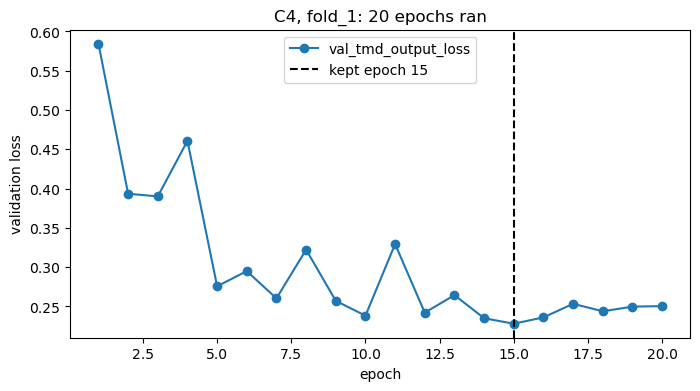

In [16]:
# What fitting produced in the real Final V2 run of this case and fold: the kept epoch is the one
# with the lowest watched validation loss.
history = pd.read_csv(SAVED_V2 / CASE_FOLDERS[CASE] / f"{FOLD}_history.csv")
watched = "val_tmd_output_loss" if multi_task else "val_loss"
best = int(history[watched].idxmin())
figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(history.index + 1, history[watched], marker="o", label=watched)
axis.axvline(best + 1, color="black", linestyle="--", label=f"kept epoch {best + 1}")
axis.set_xlabel("epoch"); axis.set_ylabel("validation loss"); axis.legend(); axis.set_title(f"{CASE}, {FOLD}: {len(history)} epochs ran")
plt.show()

In [17]:
# Train this case and fold from scratch (Modules 2 to 6 in one call). Off by default; about an hour on the RTX 4050.
# Results go to results/notebook_runs/, never to results/final_v2.
if RUN_TRAINING:
    run_one_fold(FOLDS_ROOT / FOLD, config)
else:
    print("Training is switched off. Set RUN_TRAINING = True in the settings cell to run it.")

Training is switched off. Set RUN_TRAINING = True in the settings cell to run it.


## Module 6. Evaluation and Interpretation

**What it does.** Runs the selected model once over the test lane and records, for every test image, the true label, the predicted label and the confidence. The proposed model also records its predicted artifact. From these come:

- the confusion matrix (true/false Normal and Subluxation counts),
- accuracy, precision, recall, specificity and F1-score,
- the calibration error (ECE), and the speed in images per second,
- for the proposed model, how well it recognized each artifact.

Grad-CAM is a separate branch: it needs the **saved checkpoint** from Module 5 and one processed image, and draws where the predicted class score is most sensitive.

The demo below loads the saved Final V2 checkpoint for this case and fold, scores its test fold again, and compares the numbers with the saved Final V2 result file.

In Figure 4.1 this is Module 6.

In [18]:
show(collect_predictions)
show(expected_calibration_error)
show(gradcam)

```python
def collect_predictions(
    model: Model,
    generator: TMJSequence,
    multi_task: bool,
    tta: bool | None = None,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, List[str]]:
    if tta is None:
        tta = getattr(generator, "recipe", "v2") == "v3"
    y_true: List[int] = []
    y_pred: List[int] = []
    y_conf: List[float] = []
    artifact_true: List[int] = []
    artifact_pred: List[int] = []
    artifact_conf: List[float] = []
    filepaths: List[str] = []
    infer = inference_fn(model, generator)

    for i in range(len(generator)):
        start = i * generator.batch_size
        stop = min((i + 1) * generator.batch_size, len(generator.df))
        batch_indices = generator.indices[start:stop]
        batch_df = generator.df.iloc[batch_indices]
        batch_paths = batch_df["filepath"].tolist()
        x, y = unpack_batch(generator[i])
        pred = infer(x)
        if tta:
            # Horizontal-flip test-time augmentation: average both softmax outputs.
            flipped = infer(np.ascontiguousarray(x[:, :, ::-1, :]))
            pred = (
                {key: (np.asarray(pred[key]) + np.asarray(flipped[key])) / 2 for key in pred}
                if multi_task
                else (np.asarray(pred) + np.asarray(flipped)) / 2
            )
        if multi_task:
            pred_tmd = np.asarray(pred["tmd_output"])
            pred_artifact = np.asarray(pred["artifact_output"])
            true_tmd = y["tmd_output"]
            true_artifact = y["artifact_output"]
            artifact_true.extend(np.argmax(true_artifact, axis=1).tolist())
            artifact_pred.extend(np.argmax(pred_artifact, axis=1).tolist())
            artifact_conf.extend(np.max(pred_artifact, axis=1).tolist())
        else:
            pred_tmd = np.asarray(pred)
            true_tmd = y
            artifact_true.extend(
                generator.evaluation_artifact_label(filepath) for filepath in batch_paths
            )

        y_true.extend(np.argmax(true_tmd, axis=1).tolist())
        y_pred.extend(np.argmax(pred_tmd, axis=1).tolist())
        y_conf.extend(np.max(pred_tmd, axis=1).tolist())
        filepaths.extend(batch_paths)

    return (
        np.asarray(y_true),
        np.asarray(y_pred),
        np.asarray(y_conf),
        np.asarray(artifact_true),
        np.asarray(artifact_pred),
        np.asarray(artifact_conf),
        filepaths,
    )

```

```python
def expected_calibration_error(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    confidence: np.ndarray,
    n_bins: int = 10,
) -> float:
    if not (len(y_true) == len(y_pred) == len(confidence)):
        raise ValueError("ECE arrays must have equal length.")
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    correct = (y_true == y_pred).astype(np.float64)
    ece = 0.0
    for index in range(n_bins):
        lower, upper = edges[index], edges[index + 1]
        mask = (confidence > lower) & (confidence <= upper)
        if index == 0:
            mask |= confidence == 0.0
        if mask.any():
            ece += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return float(ece)

```

```python
def gradcam(
    model: tf.keras.Model,
    inputs: np.ndarray,
    target_layer_name: str,
    class_index: int | None,
) -> Tuple[np.ndarray, np.ndarray, int]:
    target_layer = model.get_layer(target_layer_name)
    tmd_output = model.get_layer("tmd_output").output
    gradient_model = tf.keras.Model(model.inputs, [target_layer.output, tmd_output])

    with tf.GradientTape() as tape:
        feature_maps, probabilities = gradient_model(inputs, training=False)
        if class_index is None:
            class_index = int(tf.argmax(probabilities[0]))
        target_score = probabilities[:, class_index]

    gradients = tape.gradient(target_score, feature_maps)
    if gradients is None:
        raise RuntimeError(f"No gradient reached target layer {target_layer_name!r}.")
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.reduce_sum(weights * feature_maps, axis=-1)[0]
    heatmap = tf.maximum(heatmap, 0)
    maximum = tf.reduce_max(heatmap)
    heatmap = tf.where(maximum > 0, heatmap / maximum, heatmap)
    return (
        np.asarray(heatmap, dtype=np.float32),
        np.asarray(probabilities[0], dtype=np.float32),
        class_index,
    )

```

In [19]:
# Score the saved Final V2 model on its test fold and compare with the saved results.
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

if RUN_EVALUATION:
    checkpoint = SAVED_V2 / CASE_FOLDERS[CASE] / f"{FOLD}_{CASE_FOLDERS[CASE]}_best.keras"
    model = tf.keras.models.load_model(checkpoint, custom_objects={"AttentionBlock": AttentionBlock}, compile=False)
    test_gen = TMJSequence(fold_df[fold_df.split == "test"], (224, 224), 8, multi_task, scenario, False, 42)
    y_true, y_pred, y_conf, artifact_true, artifact_pred, artifact_conf, paths = collect_predictions(model, test_gen, multi_task)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    recomputed = {
        "accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred), "specificity": tn / (tn + fp), "f1": f1_score(y_true, y_pred),
        "ece_10_bins": expected_calibration_error(y_true, y_pred, y_conf, n_bins=10),
    }
    saved = pd.read_csv(SAVED_V2 / CASE_FOLDERS[CASE] / f"{FOLD}_results.csv").iloc[0]
    comparison = pd.DataFrame({"recomputed now": recomputed, "saved Final V2": {k: saved[k] for k in recomputed}}).round(4)
    print(f"{CASE}, {FOLD}: {len(y_true)} test images | TN {tn}, FP {fp}, FN {fn}, TP {tp}")
    display(comparison)
else:
    print("Evaluation is switched off. Set RUN_EVALUATION = True in the settings cell.")

E0000 00:00:1794149923.357690    5602 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


C4, fold_1: 601 test images | TN 233, FP 39, FN 30, TP 299


,recomputed now,saved Final V2
accuracy,0.8852,0.8852
precision,0.8846,0.8846
recall,0.9088,0.9088
specificity,0.8566,0.8566
f1,0.8966,0.8966
ece_10_bins,0.0596,0.0596


/home/solyvie/environments/miniforge3/envs/thesis-env/lib/python3.13/site-packages/keras/src/models/functional.py:258: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


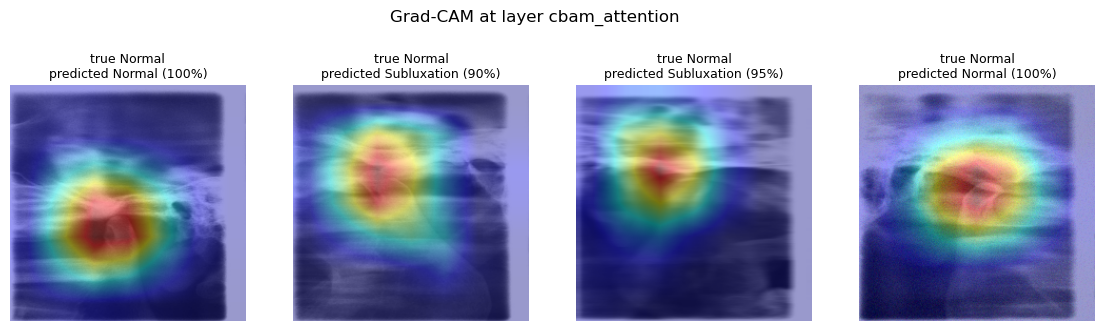

In [20]:
# Grad-CAM for the first four test images, from the saved checkpoint.
if RUN_EVALUATION:
    x, _ = test_gen[0][:2]
    figure, axes = plt.subplots(1, 4, figsize=(14, 4))
    for i, axis in enumerate(axes):
        heatmap, probabilities, class_index = gradcam(model, x[i:i + 1], TARGET_LAYERS[model_type], None)
        # Under mixed precision the V2 gradcam returns float16, which OpenCV cannot resize; later code converts inside gradcam.
        heatmap = heatmap.astype(np.float32)
        display_rgb = np.clip((x[i] + 1.0) * 127.5, 0, 255).astype(np.uint8)
        axis.imshow(overlay_heatmap(display_rgb, heatmap, 0.4))
        axis.set_title(f"true {DISPLAY_LABELS[y_true[i]]}\npredicted {DISPLAY_LABELS[class_index]} ({probabilities[class_index]:.0%})", fontsize=9)
        axis.axis("off")
    figure.suptitle(f"Grad-CAM at layer {TARGET_LAYERS[model_type]}")
    plt.show()

## One case and fold from start to end

`run_one_fold` is the function that runs one case on one fold. It calls the modules in order:

| Line in `run_one_fold` | Module and job |
|---|---|
| `df = index_split_dataset(fold_root, verify_integrity=config.verify_integrity)` | Module 2: read the fold and check it |
| `class_weights = balanced_class_weights(train_df["tmd_label"]) if config.class_weighting else None` | Module 5: compute class weights |
| `train_gen = TMJSequence(` | Module 3: build the three lanes |
| `model = build_proposed_model(config) if multi_task else build_benchmark_model(config)` | Module 4: build the benchmark or the proposed model |
| `compile_model(model, config)` | Module 5: set loss, weights and optimizer |
| `history_df = fit_model(` | Module 5: train with the three callbacks and keep the best epoch |
| `) = collect_predictions(model, evaluation_gen, multi_task)` | Module 6: predict the test lane |
| `result_df = pd.DataFrame(` | Module 6: compute the metrics |
| `result_df.to_csv(case_dir / f"{fold_root.name}_results.csv", index=False)` | Module 6: save results, predictions and history |

`run_case` repeats `run_one_fold` for each fold and then averages the results. The final runs used `run_case_5fold_isolated.py`, which starts a fresh process for each fold so that no memory is shared between folds.

In [21]:
show(run_one_fold)
show(run_case)

```python
def run_one_fold(fold_root: Path, config: RunConfig) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    print(f"\n=== Running {config.model_type} | {config.scenario} | {fold_root.name} ===")
    seed_everything(config.random_state)

    df = index_split_dataset(fold_root, verify_integrity=config.verify_integrity)
    train_df = df[df["split"] == "train"].reset_index(drop=True)
    val_df = df[df["split"] == "validation"].reset_index(drop=True)
    test_df = df[df["split"] == "test"].reset_index(drop=True)
    evaluation_df = test_df
    print(df.groupby(["split", "class_name"]).size())
    print(f"Evaluation split: test ({len(evaluation_df)} images)")

    multi_task = config.model_type == "proposed"
    class_weights = balanced_class_weights(train_df["tmd_label"]) if config.class_weighting else None
    print("TMD class weights:", class_weights)
    train_gen = TMJSequence(
        train_df,
        config.image_size,
        config.batch_size,
        multi_task,
        config.scenario,
        True,
        config.random_state,
        tmd_class_weights=class_weights,
        recipe=config.recipe,
    )
    val_gen = TMJSequence(
        val_df,
        config.image_size,
        config.batch_size,
        multi_task,
        config.scenario,
        False,
        config.random_state,
        recipe=config.recipe,
    )
    evaluation_gen = TMJSequence(
        evaluation_df,
        config.image_size,
        config.batch_size,
        multi_task,
        config.scenario,
        False,
        config.random_state,
        recipe=config.recipe,
    )

    model = build_proposed_model(config) if multi_task else build_benchmark_model(config)
    compile_model(model, config)

    case_dir = config.output_dir
    case_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = case_dir / f"{fold_root.name}_{config.model_type}_{config.scenario}_best.keras"
    history_df = fit_model(
        model,
        train_gen,
        val_gen,
        config,
        checkpoint_path,
    )
    learning_curve_path = case_dir / f"{fold_root.name}_learning_curves.png"
    save_learning_curves(
        history_df,
        config.model_type,
        learning_curve_path,
        title=f"{fold_root.name.replace('_', ' ').title()} — {config.model_type.title()} / {config.scenario}",
    )

    # Warm up before timing.
    warmup_x, _ = unpack_batch(evaluation_gen[0])
    _ = inference_fn(model, evaluation_gen)(warmup_x)
    start = time.perf_counter()
    (
        y_true,
        y_pred,
        y_conf,
        artifact_true,
        artifact_pred,
        artifact_conf,
        prediction_paths,
    ) = collect_predictions(model, evaluation_gen, multi_task)
    elapsed = time.perf_counter() - start
    images_per_second = len(y_true) / max(elapsed, 1e-8)
    latency_ms = 1000.0 / max(images_per_second, 1e-8)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    manifest_path = fold_root / "manifest.csv"
    fold_manifest_sha256 = sha256_file(manifest_path) if manifest_path.exists() else None

    per_artifact_metrics: Dict[str, float | int] = {}
    for artifact_index, artifact_name in enumerate(ARTIFACT_LABELS):
        mask = artifact_true == artifact_index
        per_artifact_metrics[f"n_{artifact_name}"] = int(mask.sum())
        per_artifact_metrics[f"tmd_accuracy_{artifact_name}"] = (
            accuracy_score(y_true[mask], y_pred[mask]) if mask.any() else np.nan
        )
        per_artifact_metrics[f"artifact_recall_{artifact_name}"] = (
            float(np.mean(artifact_pred[mask] == artifact_index))
            if multi_task and mask.any()
            else np.nan
        )

    result_df = pd.DataFrame(
        [
            {
                "model_type": config.model_type,
                "scenario": config.scenario,
                "fold": fold_root.name,
                "accuracy": accuracy_score(y_true, y_pred),
                "precision": precision_score(y_true, y_pred, zero_division=0),
                "recall": recall_score(y_true, y_pred, zero_division=0),
                "specificity": tn / max(tn + fp, 1),
                "f1": f1_score(y_true, y_pred, zero_division=0),
                "artifact_accuracy": (
                    accuracy_score(artifact_true, artifact_pred) if multi_task else np.nan
                ),
                "artifact_macro_f1": (
                    f1_score(
                        artifact_true,
                        artifact_pred,
                        labels=list(range(len(ARTIFACT_LABELS))),
                        average="macro",
                        zero_division=0,
                    )
                    if multi_task
                    else np.nan
                ),
                "ece_10_bins": expected_calibration_error(y_true, y_pred, y_conf, n_bins=10),
                "tn": int(tn),
                "fp": int(fp),
                "fn": int(fn),
                "tp": int(tp),
                "images_per_second": images_per_second,
                "latency_ms": latency_ms,
                "learning_curve_png": str(learning_curve_path),
                "epochs_ran": len(history_df),
                "evaluation_split": "test",
                "training_protocol": TRAINING_PROTOCOLS[config.recipe],
                "tensorflow_version": tf.__version__,
                "precision_policy": mixed_precision.global_policy().name,
                "artifact_protocol": ARTIFACT_PROTOCOL,
                "class_weighting": config.class_weighting,
                "fold_manifest_sha256": fold_manifest_sha256,
                "training_script_sha256": training_source_sha256(),
                "run_config_sha256": effective_run_config_sha256(config),
                **per_artifact_metrics,
            }
        ]
    )
    cm_df = pd.DataFrame(cm, index=DISPLAY_LABELS, columns=DISPLAY_LABELS)
    pred_data: Dict[str, object] = {
        "filepath": prediction_paths,
        "y_true": y_true,
        "y_pred": y_pred,
        "confidence": y_conf,
        "artifact_true": artifact_true,
    }
    if multi_task:
        pred_data.update(
            {
                "artifact_pred": artifact_pred,
                "artifact_confidence": artifact_conf,
            }
        )
    pred_df = pd.DataFrame(pred_data)

    result_df.to_csv(case_dir / f"{fold_root.name}_results.csv", index=False)
    cm_df.to_csv(case_dir / f"{fold_root.name}_confusion_matrix.csv")
    if multi_task:
        artifact_cm = confusion_matrix(
            artifact_true,
            artifact_pred,
            labels=list(range(len(ARTIFACT_LABELS))),
        )
        pd.DataFrame(
            artifact_cm,
            index=ARTIFACT_LABELS,
            columns=ARTIFACT_LABELS,
        ).to_csv(case_dir / f"{fold_root.name}_artifact_confusion_matrix.csv")
    pred_df.to_csv(case_dir / f"{fold_root.name}_predictions.csv", index=False)
    history_df.to_csv(case_dir / f"{fold_root.name}_history.csv", index=False)

    print(result_df)
    print(cm_df)

    tf.keras.backend.clear_session()
    gc.collect()
    return result_df, cm_df, pred_df, history_df

```

```python
def run_case(config: RunConfig) -> pd.DataFrame:
    configure_tensorflow(config)
    if config.model_type not in {"benchmark", "proposed"}:
        raise ValueError("model_type must be 'benchmark' or 'proposed'")
    if config.scenario not in {"clean", "artifact_mix"}:
        raise ValueError("scenario must be 'clean' or 'artifact_mix'")

    fold_dirs = sorted(
        [p for p in config.folds_root.iterdir() if p.is_dir() and p.name.startswith("fold_")],
        key=lambda p: int(p.name.split("_")[1]),
    )
    if config.single_fold is not None:
        fold_dirs = [p for p in fold_dirs if p.name == config.single_fold]
        if not fold_dirs:
            raise FileNotFoundError(
                f"Requested --single_fold {config.single_fold!r}, but it was not found under {config.folds_root}"
            )
    if config.fold_limit is not None:
        fold_dirs = fold_dirs[: config.fold_limit]
    if not fold_dirs:
        raise FileNotFoundError(f"No fold folders found under {config.folds_root}")

    print("TensorFlow:", tf.__version__)
    print("GPU devices:", tf.config.list_physical_devices("GPU"))
    print("Config:", config)

    result_rows: List[pd.DataFrame] = []
    pooled_cm: pd.DataFrame | None = None
    config.output_dir.mkdir(parents=True, exist_ok=True)
    with (config.output_dir / "run_config.json").open("w", encoding="utf-8") as f:
        serializable = asdict(config)
        serializable["folds_root"] = str(config.folds_root)
        serializable["output_dir"] = str(config.output_dir)
        serializable["tensorflow_version"] = tf.__version__
        serializable["gpu_devices"] = [device.name for device in tf.config.list_physical_devices("GPU")]
        serializable["precision_policy"] = mixed_precision.global_policy().name
        serializable["artifact_protocol"] = ARTIFACT_PROTOCOL
        serializable["training_protocol"] = TRAINING_PROTOCOLS[config.recipe]
        serializable["training_script_sha256"] = training_source_sha256()
        serializable["effective_run_config_sha256"] = effective_run_config_sha256(config)
        json.dump(serializable, f, indent=2)

    for fold_root in fold_dirs:
        result_df, cm_df, _, _ = run_one_fold(fold_root, config)
        result_rows.append(result_df)
        pooled_cm = cm_df.copy() if pooled_cm is None else pooled_cm.add(cm_df, fill_value=0)

    combined = pd.concat(result_rows, ignore_index=True)
    combined.to_csv(config.output_dir / "all_fold_results.csv", index=False)

    metric_columns = [
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "f1",
        "ece_10_bins",
        "images_per_second",
        "latency_ms",
        "epochs_ran",
    ]
    if combined["artifact_accuracy"].notna().any():
        metric_columns.extend(["artifact_accuracy", "artifact_macro_f1"])
        metric_columns.extend(
            f"artifact_recall_{artifact_name}" for artifact_name in ARTIFACT_LABELS
        )
    summary = combined[metric_columns].agg(["mean", "std"]).T.reset_index(names="metric")
    summary.to_csv(config.output_dir / "summary_mean_std.csv", index=False)

    if pooled_cm is not None:
        pooled_cm.astype(int).to_csv(config.output_dir / "pooled_confusion_matrix.csv")

    print("\n=== Combined fold results ===")
    print(combined)
    print("\n=== Mean ± SD summary ===")
    print(summary)
    return combined

```